# Why Temperature 0 Still Gives Different Answers: a toy simulation
This notebook uses a handful of made-up token scores to show how temperature reshapes probabilities, and how tiny rounding-style noise can flip the winner when two tokens are nearly tied. It then reruns the same toy "completion" many times so you can watch identical runs stay identical for a while and then split apart.

Everything here is simulated with numpy. No real model is involved, and the numbers are chosen to make the idea visible, not to match any particular system.

## Setup
Just numpy, pandas and matplotlib. I fix the random seed to 42 so you get the same numbers I got when you run this.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## Step 1: Turn scores into probabilities with softmax
These are the toy scores (logits) from the post for the prompt "The cat sat on the". The `softmax` function below divides every score by the temperature T, applies exp, and divides by the total so everything adds up to 1.

I subtract the biggest score before calling exp. That doesn't change the result, and it keeps the numbers from getting huge.

In [2]:
tokens = ["mat", "sofa", "floor", "spreadsheet"]
scores = np.array([9.1, 8.7, 7.9, 1.2])

def softmax(scores, T):
    z = (scores - scores.max()) / T
    e = np.exp(z)
    return e / e.sum()

temperatures = [1.0, 0.5, 0.05]
table = pd.DataFrame(
    {f"T = {T}": softmax(scores, T) * 100 for T in temperatures},
    index=tokens,
).round(2)
print("Probability of each token, in percent:")
print(table)

Probability of each token, in percent:
             T = 1.0  T = 0.5  T = 0.05
mat            50.71    64.93     99.97
sofa           33.99    29.18      0.03
floor          15.27     5.89      0.00
spreadsheet     0.02     0.00      0.00


## Chart 1: Same scores, three temperatures
Here's the contrast knob from the post. At T = 1, "mat" gets about half the probability and "sofa" and "floor" still have a real chance. At T = 0.5 the gaps stretch and "mat" pulls ahead. At T = 0.05, which is as close to 0 as I need, "mat" takes almost everything. That's basically greedy decoding: highest score wins.

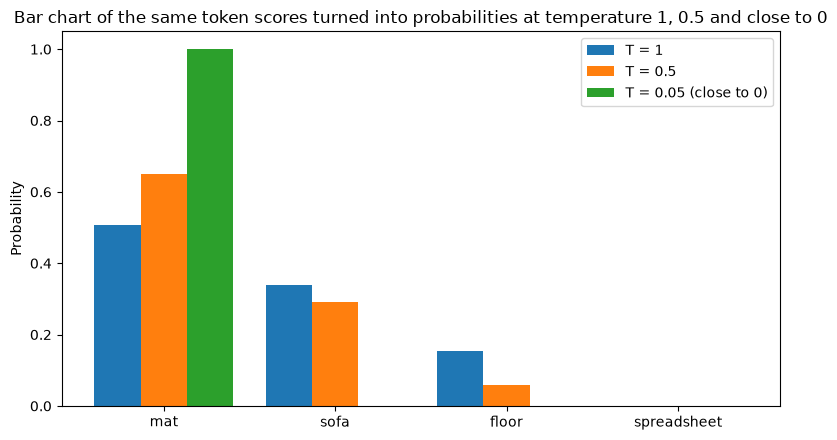

In [3]:
x = np.arange(len(tokens))
width = 0.27
labels = ["T = 1", "T = 0.5", "T = 0.05 (close to 0)"]

plt.figure(figsize=(8, 4.5))
for i, T in enumerate(temperatures):
    plt.bar(x + (i - 1) * width, softmax(scores, T), width, label=labels[i])
plt.xticks(x, tokens)
plt.ylabel("Probability")
plt.ylim(0, 1.05)
plt.legend()
plt.title("Bar chart of the same token scores turned into probabilities at temperature 1, 0.5 and close to 0")
plt.tight_layout()
plt.show()

## Step 2: Add tiny noise and see when the top token flips
At temperature 0 the rule is "pick the highest score". That's only stable if the scores come out exactly the same every time. On real hardware, rounding nudges them a little between runs.

To mimic that, I add a bit of random noise to every score and then pick the top one. On a real GPU the wobble is far out in the decimals. Here I scale it up to a standard deviation of 0.01 so the effect is easy to see. What matters is how big the gap between the top two scores is **compared to** the noise.

I keep "mat" at 9.1, put "sofa" just below it at 9.1 minus the gap, and shrink that gap step by step. For each gap I run 10,000 noisy greedy picks and count how often "mat" doesn't win. All of this data is simulated.

In [4]:
noise_std = 0.01
n_trials = 10_000
gaps = np.linspace(0.0, 0.06, 25)

flip_rates = []
for gap in gaps:
    base = np.array([9.1, 9.1 - gap, 7.9, 1.2])
    noisy = base + rng.normal(0, noise_std, size=(n_trials, len(base)))
    winners = noisy.argmax(axis=1)
    flip_rates.append(np.mean(winners != 0))
flip_rates = np.array(flip_rates)

for gap, rate in zip(gaps[::6], flip_rates[::6]):
    print(f"gap {gap:.3f}: top token flipped in {rate * 100:5.1f}% of runs")

gap 0.000: top token flipped in  50.9% of runs
gap 0.015: top token flipped in  14.2% of runs
gap 0.030: top token flipped in   1.7% of runs
gap 0.045: top token flipped in   0.1% of runs
gap 0.060: top token flipped in   0.0% of runs


## Chart 2: The closer the race, the more flips
Read this from right to left. With a wide gap, the noise never matters and "mat" wins every time. As the gap shrinks toward the size of the noise, flips start to appear. At a gap of zero it's a pure coin toss, about 50 percent. A wide gap is safe. A razor-thin gap isn't.

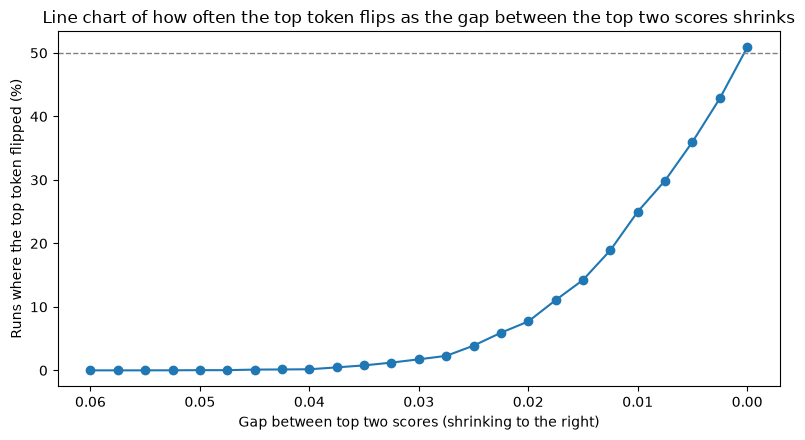

In [5]:
plt.figure(figsize=(8, 4.5))
plt.plot(gaps, flip_rates * 100, marker="o")
plt.gca().invert_xaxis()
plt.xlabel("Gap between top two scores (shrinking to the right)")
plt.ylabel("Runs where the top token flipped (%)")
plt.axhline(50, color="grey", linestyle="--", linewidth=1)
plt.title("Line chart of how often the top token flips as the gap between the top two scores shrinks")
plt.tight_layout()
plt.show()

## Step 3: Rerun a whole "completion" many times
Now I chain tokens together. I make a toy completion that's 300 tokens long. At each position there's a gap between the top two candidates. Most gaps are comfortable, and a few are close calls. I draw these gaps once, because the prompt is the same for every run.

Then I run the completion 1,000 times. Each time, every position gets its own fresh bit of noise, and the greedy pick goes to whichever of the two candidates comes out ahead.

I compare every run to the first run. The moment a run picks a different token, its text is different. From then on the model would be continuing a different sentence, so that run counts as "split off" for good. It never comes back. That's the hiker taking a different fork. `np.cumprod` handles this: once a position doesn't match, everything after it counts as not identical.

I tuned the gap sizes so that roughly 1 token in 100 is a real close call. That's the same made-up rate from the post. As before, the data is simulated.

In [6]:
n_runs = 1_000
n_tokens = 300
position_gaps = rng.exponential(scale=1.0, size=n_tokens)

noise = rng.normal(0, noise_std, size=(n_runs, n_tokens, 2))
picked_second = (position_gaps + noise[:, :, 0] - noise[:, :, 1]) < 0
choices = picked_second.astype(int)

matches_first = choices[1:] == choices[0]
still_identical = np.cumprod(matches_first, axis=1)
share_identical = still_identical.mean(axis=0)

positions = np.arange(1, n_tokens + 1)
reference = 0.99 ** positions

print(f"Close calls (gap < 0.02) in this completion: {np.sum(position_gaps < 0.02)} of {n_tokens} positions")
for n in [10, 50, 100, 200, 300]:
    print(f"after {n:3d} tokens: {share_identical[n - 1] * 100:5.1f}% of runs still identical to run 1")
below_half = np.argmax(share_identical < 0.5)
if share_identical[below_half] < 0.5:
    print(f"Fewer than half the runs match from token {below_half + 1} onward")

Close calls (gap < 0.02) in this completion: 4 of 300 positions
after  10 tokens: 100.0% of runs still identical to run 1
after  50 tokens:  99.0% of runs still identical to run 1
after 100 tokens:  31.8% of runs still identical to run 1
after 200 tokens:  27.7% of runs still identical to run 1
after 300 tokens:  19.7% of runs still identical to run 1
Fewer than half the runs match from token 67 onward


## Chart 3: Long agreement, then a split that doesn't heal
The blue line is the simulation. It stays flat through the easy tokens, then drops in sudden steps exactly where a close call shows up. Those drops are where runs split. The dashed line is the rough formula from the post, (1 - 0.01) to the power n, which lands near 37 percent at 100 tokens. The simulation follows the same overall slide, just in lumpier steps because real close calls come at specific positions.

Small risks per token, repeated many times, plus the fact that one flip changes everything after it. That's why identical temperature-0 runs look stable for a while and then fall apart.

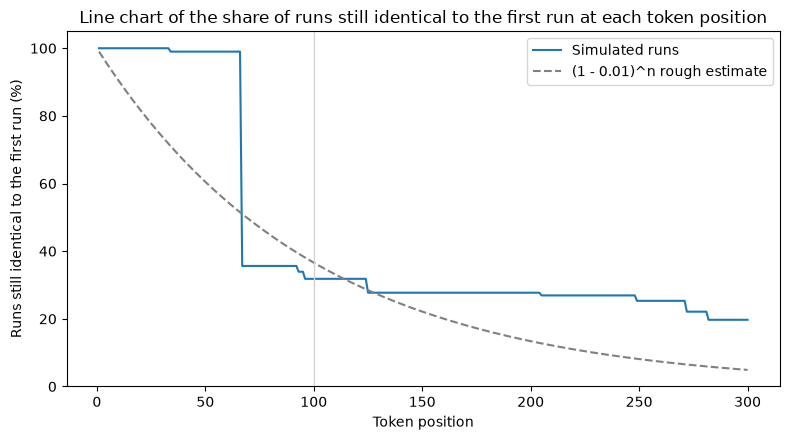

In [7]:
plt.figure(figsize=(8, 4.5))
plt.plot(positions, share_identical * 100, label="Simulated runs")
plt.plot(positions, reference * 100, linestyle="--", color="grey", label="(1 - 0.01)^n rough estimate")
plt.axvline(100, color="lightgrey", linewidth=1)
plt.xlabel("Token position")
plt.ylabel("Runs still identical to the first run (%)")
plt.ylim(0, 105)
plt.legend()
plt.title("Line chart of the share of runs still identical to the first run at each token position")
plt.tight_layout()
plt.show()

## What to take away
Temperature 0 only means "always pick the top token". It doesn't promise that the scores themselves are identical. Close calls plus tiny noise give you occasional flips, and one flip sends the rest of the answer down a different path.

Try changing `noise_std`, or the `scale` of the gaps in Step 3, and rerun. Watch how fast the curve in Chart 3 drops. Then go back to your own automation and make its output checkable instead of hoping it stays identical.